## ÁNALISIS DEL DATASET MEDIANTE CREACIÓN GRAPHS

Mes con más intervenciones: Junio 13133
Mes con menos intervenciones: Agosto 10469


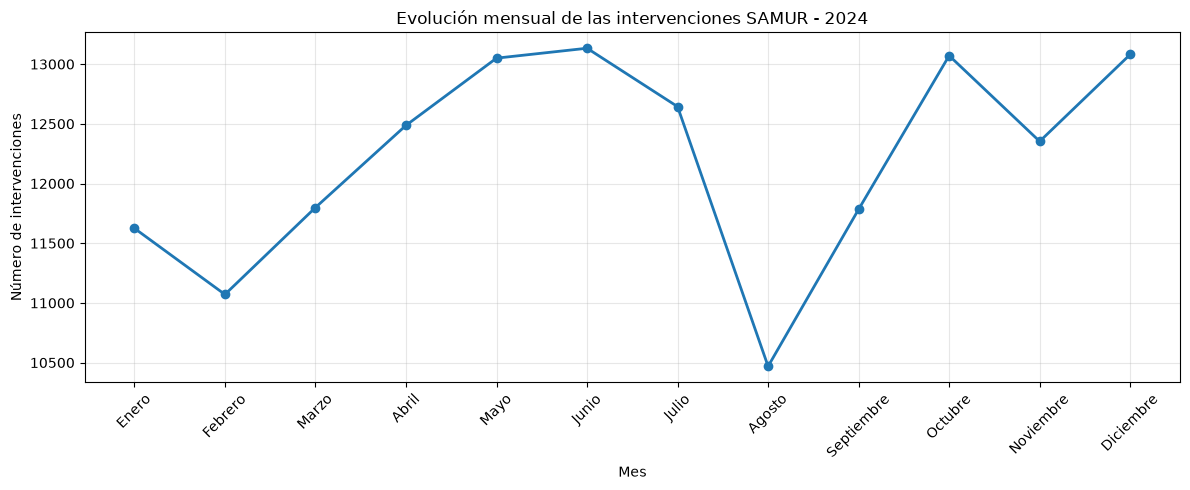

In [2]:
import matplotlib.pyplot as plt
import calendar
import pandas as pd
dataset_modelado = pd.read_csv(r"C:\Users\bario\OneDrive\Documentos\UC3M\PROYECTO EN CIENCIA DE DATOS\proyecto_emergencias-20260915T155207Z-1-001\proyecto_emergencias\datasets limpios\dataset_samur_modelado.csv")

# 1. Agrupar las intervenciones por mes
intervenciones_mes = (
    dataset_modelado
    .groupby('mes_num')['total_intervenciones']
    .sum()
    .reset_index()
    .sort_values('mes_num')
)

# 2. Añadir nombre del mes
meses_es = [
    'Enero', 'Febrero', 'Marzo', 'Abril',
    'Mayo', 'Junio', 'Julio', 'Agosto',
    'Septiembre', 'Octubre', 'Noviembre', 'Diciembre'
]

intervenciones_mes['mes_nombre'] = meses_es

# 3. Identificar máximos y mínimos
mes_max = intervenciones_mes.loc[
    intervenciones_mes['total_intervenciones'].idxmax()
]

mes_min = intervenciones_mes.loc[
    intervenciones_mes['total_intervenciones'].idxmin()
]

print("Mes con más intervenciones:",
      mes_max['mes_nombre'],
      int(mes_max['total_intervenciones']))

print("Mes con menos intervenciones:",
      mes_min['mes_nombre'],
      int(mes_min['total_intervenciones']))

# 4. Representar evolución mensual
plt.figure(figsize=(12, 5))

plt.plot(
    intervenciones_mes['mes_nombre'],
    intervenciones_mes['total_intervenciones'],
    marker='o',
    linewidth=2
)

plt.title('Evolución mensual de las intervenciones SAMUR - 2024')
plt.xlabel('Mes')
plt.ylabel('Número de intervenciones')
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

,franja_horaria,total_intervenciones,porcentaje
0,1. Madrugada (00:00 - 05:59),20562,14.166523
1,2. Mañana (06:00 - 11:59),31007,21.362775
2,3. Tarde (12:00 - 17:59),50621,34.876158
3,4. Noche (18:00 - 23:59),42955,29.594543


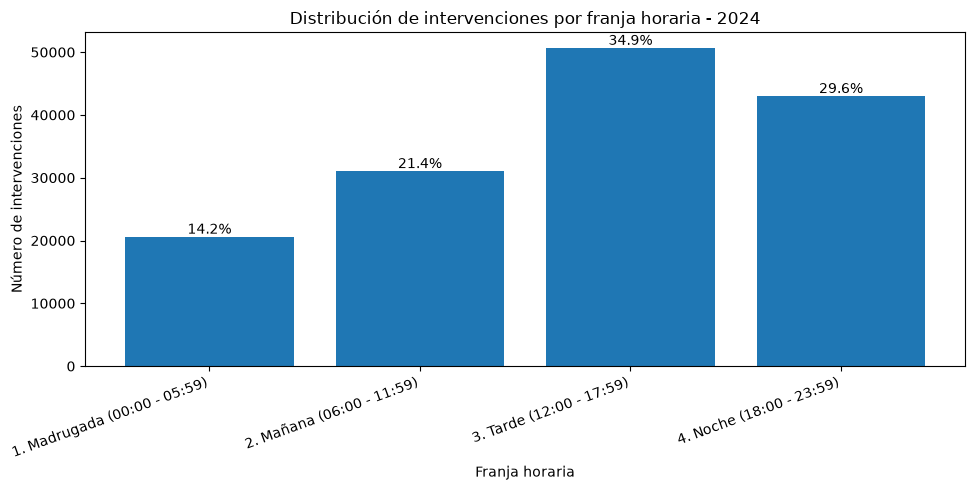

In [4]:
# 1. Agrupar intervenciones por franja horaria
intervenciones_franja = (
    dataset_modelado
    .groupby('franja_horaria')['total_intervenciones']
    .sum()
    .reset_index()
)

# 2. Excluir Desconocido SOLO de la visualización
# Conservamos todos los datos en el dataset original
orden_franjas = [
    '1. Madrugada (00:00 - 05:59)',
    '2. Mañana (06:00 - 11:59)',
    '3. Tarde (12:00 - 17:59)',
    '4. Noche (18:00 - 23:59)'
]

intervenciones_franja_real = (
    intervenciones_franja[
        intervenciones_franja['franja_horaria'].isin(orden_franjas)
    ]
    .copy()
)

intervenciones_franja_real['franja_horaria'] = pd.Categorical(
    intervenciones_franja_real['franja_horaria'],
    categories=orden_franjas,
    ordered=True
)

intervenciones_franja_real = (
    intervenciones_franja_real
    .sort_values('franja_horaria')
)

# 3. Calcular porcentajes sobre el total de las cuatro franjas conocidas
total_conocido = intervenciones_franja_real[
    'total_intervenciones'
].sum()

intervenciones_franja_real['porcentaje'] = (
    intervenciones_franja_real['total_intervenciones']
    / total_conocido * 100
)

display(intervenciones_franja_real)

# 4. Representar distribución
plt.figure(figsize=(10, 5))

barras = plt.bar(
    intervenciones_franja_real['franja_horaria'].astype(str),
    intervenciones_franja_real['total_intervenciones']
)

plt.title('Distribución de intervenciones por franja horaria - 2024')
plt.xlabel('Franja horaria')
plt.ylabel('Número de intervenciones')
plt.xticks(rotation=20, ha='right')

# Añadir porcentajes encima de las barras
for barra, porcentaje in zip(
    barras,
    intervenciones_franja_real['porcentaje']
):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height(),
        f'{porcentaje:.1f}%',
        ha='center',
        va='bottom'
    )

plt.tight_layout()
plt.show()

TOP 5 DISTRITOS POR NÚMERO DE INTERVENCIONES


,distrito,total_intervenciones,poblacion,intervenciones_1000_hab
3,CENTRO,21182,149718.0,141.479314
2,CARABANCHEL,10421,257329.0,40.496796
12,PUENTE DE VALLECAS,9698,244458.0,39.671436
9,LATINA,8314,233765.0,35.565632
10,MONCLOA-ARAVACA,7995,123606.0,64.681326


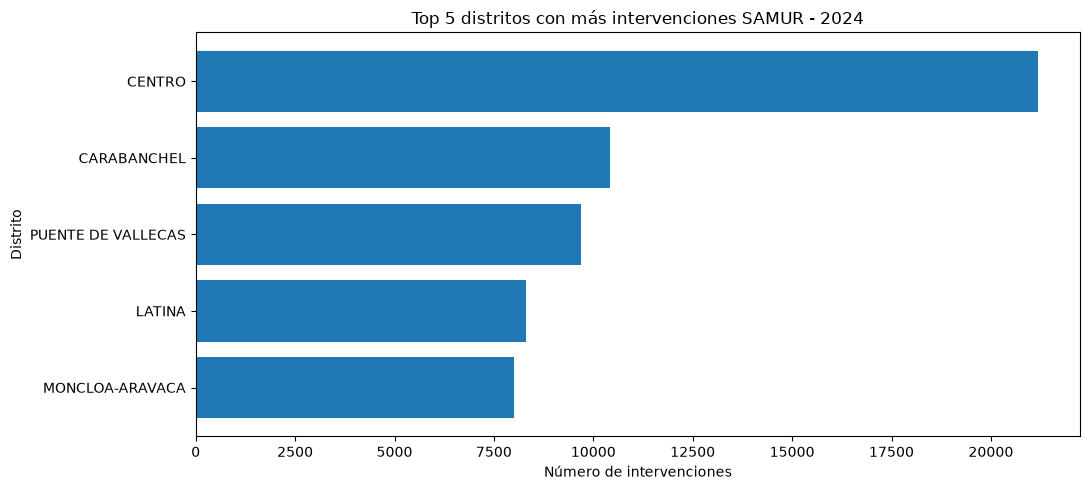

TOP 5 DISTRITOS POR CADA 1.000 HABITANTES


,distrito,total_intervenciones,poblacion,intervenciones_1000_hab
3,CENTRO,21182,149718.0,141.479314
10,MONCLOA-ARAVACA,7995,123606.0,64.681326
16,TETUAN,7957,155159.0,51.282878
14,SALAMANCA,7523,147707.0,50.931913
5,CHAMBERI,7001,137532.0,50.904517


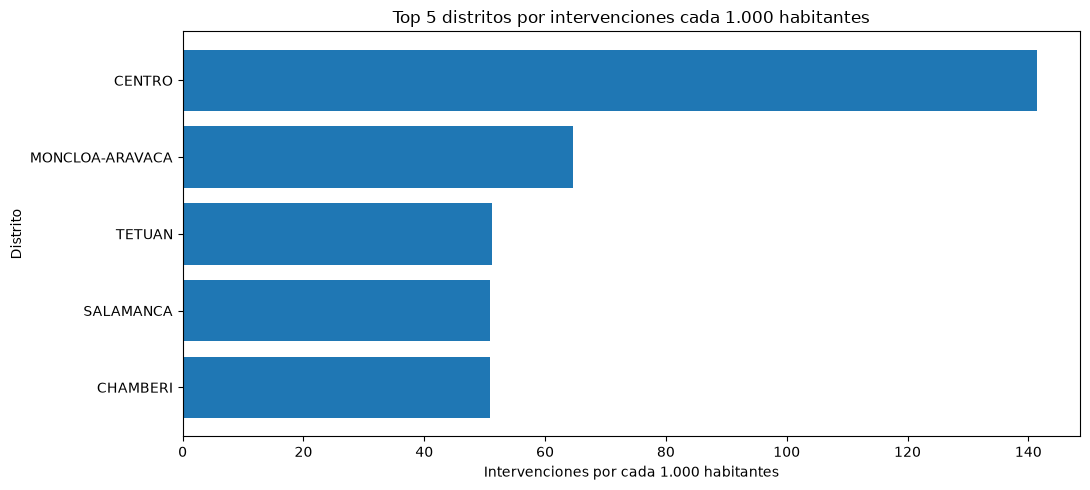

In [5]:
# 1. Agrupar intervenciones por distrito
intervenciones_distrito = (
    dataset_modelado[
        dataset_modelado['distrito'] != 'OTROS / DISTRITO NO IDENTIFICADO'
    ]
    .groupby('distrito')
    .agg(
        total_intervenciones=('total_intervenciones', 'sum'),
        poblacion=('poblacion', 'first')
    )
    .reset_index()
)

# 2. Calcular intervenciones por cada 1.000 habitantes
intervenciones_distrito['intervenciones_1000_hab'] = (
    intervenciones_distrito['total_intervenciones']
    / intervenciones_distrito['poblacion'] * 1000
)

# 3. Mostrar los cinco distritos con más intervenciones
top_distritos = intervenciones_distrito.sort_values(
    'total_intervenciones',
    ascending=False
).head(5)

print("TOP 5 DISTRITOS POR NÚMERO DE INTERVENCIONES")
display(top_distritos)

# 4. Gráfico de intervenciones absolutas
plt.figure(figsize=(11, 5))

plt.barh(
    top_distritos.sort_values('total_intervenciones')['distrito'],
    top_distritos.sort_values('total_intervenciones')['total_intervenciones']
)

plt.title('Top 5 distritos con más intervenciones SAMUR - 2024')
plt.xlabel('Número de intervenciones')
plt.ylabel('Distrito')
plt.tight_layout()
plt.show()

# 5. Top 5 por tasa de intervenciones por población
top_tasa = intervenciones_distrito.sort_values(
    'intervenciones_1000_hab',
    ascending=False
).head(5)

print("TOP 5 DISTRITOS POR CADA 1.000 HABITANTES")
display(top_tasa)

# 6. Gráfico de tasas
plt.figure(figsize=(11, 5))

plt.barh(
    top_tasa.sort_values('intervenciones_1000_hab')['distrito'],
    top_tasa.sort_values('intervenciones_1000_hab')['intervenciones_1000_hab']
)

plt.title('Top 5 distritos por intervenciones cada 1.000 habitantes')
plt.xlabel('Intervenciones por cada 1.000 habitantes')
plt.ylabel('Distrito')
plt.tight_layout()
plt.show()

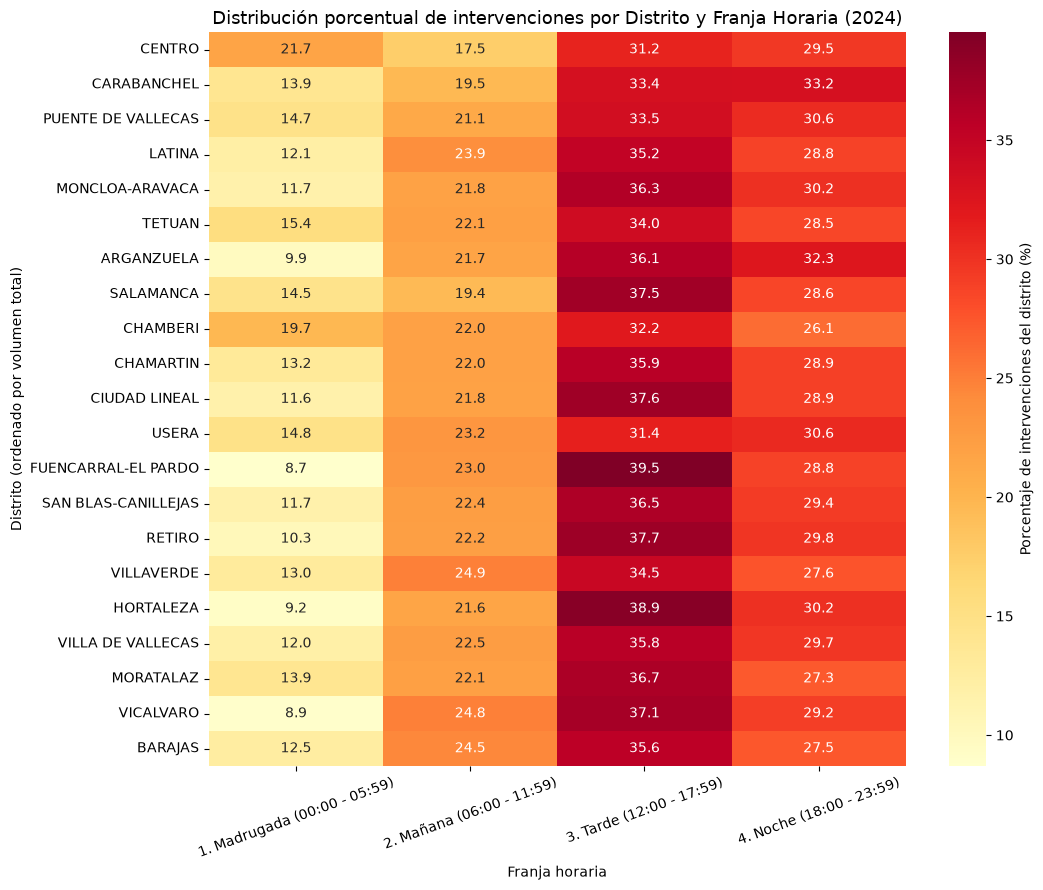

In [3]:
import seaborn as sns
import matplotlib.pyplot as plt

# Filtrar distritos oficiales y franjas horarias conocidas
df_eda = dataset_modelado[
    (dataset_modelado['distrito'] != 'OTROS / DISTRITO NO IDENTIFICADO') &
    (dataset_modelado['franja_horaria'] != 'Desconocido')
].copy()

# Crear tabla dinámica (Distrito x Franja) y calcular el % por fila (distrito)
tabla_distrito_franja = df_eda.pivot_table(
    index='distrito',
    columns='franja_horaria',
    values='total_intervenciones',
    aggfunc='sum'
)

# Ordenar distritos por volumen total de intervenciones (de mayor a menor)
orden_distritos = tabla_distrito_franja.sum(axis=1).sort_values(ascending=False).index
tabla_distrito_franja = tabla_distrito_franja.loc[orden_distritos]

# Convertir a porcentaje dentro de cada distrito
tabla_pct = tabla_distrito_franja.div(tabla_distrito_franja.sum(axis=1), axis=0) * 100

# Representar Heatmap
plt.figure(figsize=(11, 9))
sns.heatmap(
    tabla_pct,
    annot=True,
    fmt='.1f',
    cmap='YlOrRd',
    cbar_kws={'label': 'Porcentaje de intervenciones del distrito (%)'}
)

plt.title('Distribución porcentual de intervenciones por Distrito y Franja Horaria (2024)', fontsize=13)
plt.xlabel('Franja horaria')
plt.ylabel('Distrito (ordenado por volumen total)')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

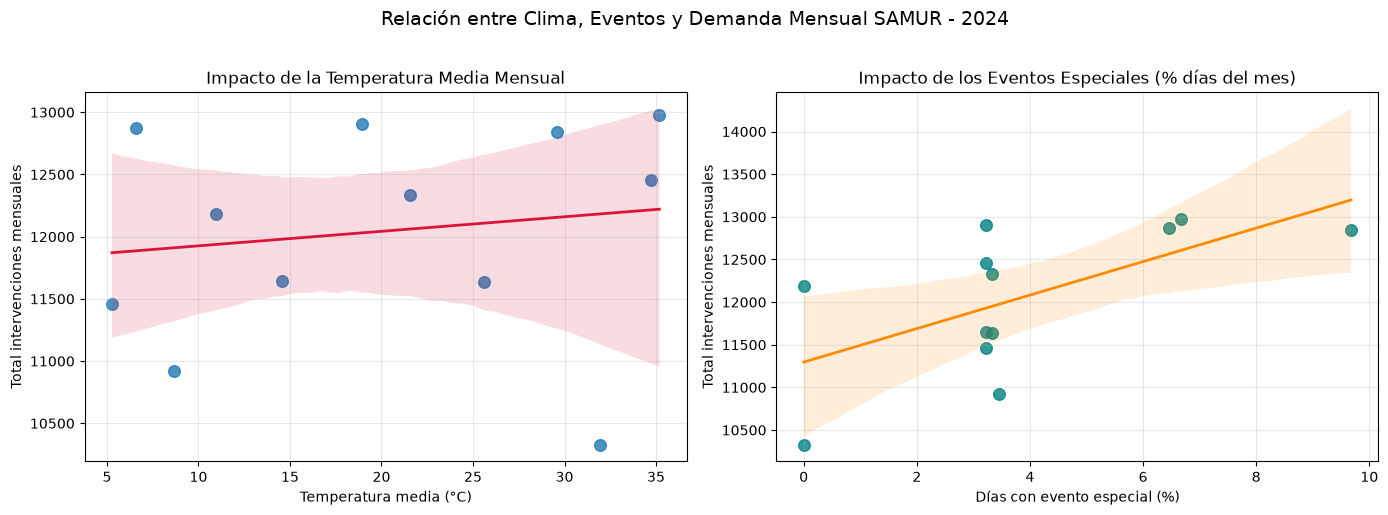

In [4]:
# Agregar a nivel mensual (excluyendo OTROS y Desconocido para coherencia operativa)
df_mensual_eda = df_eda.groupby('mes_num', as_index=False).agg(
    total_intervenciones=('total_intervenciones', 'sum'),
    temperatura_media=('temperatura_media', 'first'),
    dias_calor_extremo=('dias_calor_extremo', 'first'),
    pct_dias_evento=('pct_dias_evento', 'first'),
    dias_lluvia=('dias_lluvia', 'first')
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Panel 1: Temperatura media vs Intervenciones mensuales
sns.regplot(
    data=df_mensual_eda,
    x='temperatura_media',
    y='total_intervenciones',
    ax=axes[0],
    scatter_kws={'s': 70, 'alpha': 0.8},
    line_kws={'color': 'crimson', 'linewidth': 2}
)
axes[0].set_title('Impacto de la Temperatura Media Mensual')
axes[0].set_xlabel('Temperatura media (°C)')
axes[0].set_ylabel('Total intervenciones mensuales')
axes[0].grid(alpha=0.3)

# Panel 2: Porcentaje de días con eventos especiales vs Intervenciones mensuales
sns.regplot(
    data=df_mensual_eda,
    x='pct_dias_evento',
    y='total_intervenciones',
    ax=axes[1],
    scatter_kws={'s': 70, 'alpha': 0.8, 'color': 'teal'},
    line_kws={'color': 'darkorange', 'linewidth': 2}
)
axes[1].set_title('Impacto de los Eventos Especiales (% días del mes)')
axes[1].set_xlabel('Días con evento especial (%)')
axes[1].set_ylabel('Total intervenciones mensuales')
axes[1].grid(alpha=0.3)

plt.suptitle('Relación entre Clima, Eventos y Demanda Mensual SAMUR - 2024', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

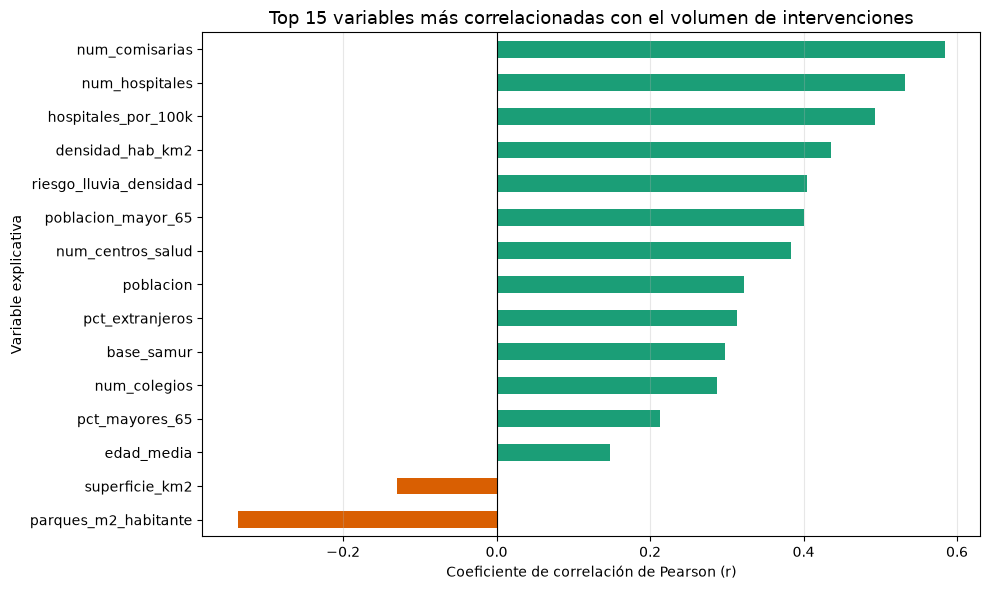

In [5]:
# Seleccionar solo columnas numéricas (excluyendo identificadores sin sentido lineal)
cols_excluir = ['mes_num', 'distrito_id', 'codigo_postal_principal']
df_num = df_eda.select_dtypes(include=['number']).drop(columns=cols_excluir, errors='ignore')

# Calcular correlación de Pearson con la variable objetivo
correlaciones = (
    df_num.corr()['total_intervenciones']
    .drop('total_intervenciones')
    .dropna()
)

# Seleccionar las 15 con mayor correlación absoluta
top_15_corr = correlaciones.reindex(
    correlaciones.abs().sort_values(ascending=False).head(15).index
).sort_values()

# Representar barras horizontales diferenciando signo positivo y negativo
colores = ['#d95f02' if val < 0 else '#1b9e77' for val in top_15_corr]

plt.figure(figsize=(10, 6))
top_15_corr.plot(kind='barh', color=colores)

plt.axvline(0, color='black', linewidth=0.8)
plt.title('Top 15 variables más correlacionadas con el volumen de intervenciones', fontsize=13)
plt.xlabel('Coeficiente de correlación de Pearson (r)')
plt.ylabel('Variable explicativa')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()

## ANÁLISIS DE LOS GRÁFICOS
* **Gráfico 1 — Evolución mensual de las intervenciones SAMUR (2024):**
  * **Qué muestra:** La serie temporal del volumen total de activaciones a lo largo de los 12 meses del año.
  * **Análisis:** Se observa una marcada estacionalidad con un máximo anual en primavera tardía (**junio**, con **13.133 intervenciones**, seguido muy de cerca por mayo, octubre y diciembre por encima de las 13.000) y una caída brusca en **agosto** (**10.469 intervenciones**, un -20,3 % respecto al pico) explicada por el descenso de población flotante y actividad laboral durante las vacaciones de veranO.

* **Gráfico 2 — Distribución de intervenciones por franja horaria:**
  * **Qué muestra:** El peso porcentual de cada tramo horario de 6 horas sobre el total de activaciones con hora válida.
  * **Análisis:** Casi dos tercios de la demanda diaria (**64,5 %**) se concentran en la segunda mitad del día: la **Tarde (12:00–17:59)** lidera con el **34,9 %**, seguida de la **Noche (18:00–23:59)** con el **29,6 %**, mientras que la **Mañana (06:00–11:59)** supone el **21,4 %** y la **Madrugada (00:00–05:59)** cae hasta el **14,2 %**.

* **Gráfico 3 — Top 5 distritos con más intervenciones absolutas:**
  * **Qué muestra:** Ranking de los cinco distritos que acumulan mayor número bruto de emergencias en 2024.
  * **Análisis:** **Centro** encabeza la clasificación con más de **21.000 intervenciones**, duplicando al segundo distrito (**Carabanchel**, ~10.400) y superando ampliamente a otros distritos de gran tamaño poblacional como **Puente de Vallecas**, **Latina** y **Moncloa-Aravaca**.
* **Gráfico 4 — Top 5 distritos por intervenciones cada 1.000 habitantes:**
  * **Qué muestra:** Incidencia relativa ajustada por la población empadronada de cada distrito.
  * **Análisis:** Al relativizar por población, se aisla el efecto de la **población flotante** (turismo, ocio, movilidad laboral y universitaria): **Centro** dispara su tasa hasta superar las **141 intervenciones por cada 1.000 habitantes** (casi el triple que el resto), y distritos periféricos populosos salen del Top 5 dejando paso a distritos centrales de alta actividad terciaria como **Moncloa-Aravaca** (~65), **Tetuán**, **Salamanca** y **Chamberí** (~51).

* **Gráfico 5 — Mapa de calor: Distribución porcentual por Distrito y Franja Horaria:**
  * **Qué muestra:** El perfil horario relativo (suma 100 % por fila) dentro de cada uno de los 21 distritos oficiales, ordenados de mayor a menor volumen total.
  * **Análisis:** Confirma una fuerte interacción espacio-temporal. Mientras que distritos residenciales o periféricos concentran casi el 40 % de su actividad por la tarde y apenas un 8,7 %–9,2 % de madrugada (**Fuencarral-El Pardo**, **Vícalvaro**, **Hortaleza**), los distritos con intensa vida nocturna presentan un peso de madrugada que duplica la media: **Centro** alcanza el **21,7 %** y **Chamberí** el **19,7 %** de sus intervenciones entre las 00:00 y las 05:59.

* **Gráfico 6 — Relación entre Clima, Eventos Especiales y Demanda Mensual:**
  * **Qué muestra:** Dos diagramas de dispersión con recta de regresión lineal comparando el total de intervenciones mensuales frente a la temperatura media (°C) y frente al porcentaje de días con eventos especiales en el mes.
  * **Análisis:**
    * *Temperatura media:* Muestra una pendiente ligeramente positiva pero muy dispersa, debido al **efecto distorsionador de agosto** (el punto atípico inferior derecho a ~32 °C con solo ~10.350 intervenciones en distritos oficiales, donde el calor extremo coincide con el vaciamiento vacacional de Madrid). Esto demuestra que la relación entre temperatura y demanda **no es lineal simple**, justificando el uso de modelos basados en árboles y términos de interacción.
    * *Eventos especiales:* Presenta una **clara correlación positiva**: a medida que aumenta el porcentaje de días con eventos en el mes (desde el 0 % en agosto hasta cerca del 10 % en meses con alta agenda cultural/deportiva), la demanda mensual escala de forma sostenida hacia las 13.000 intervenciones.

* **Gráfico 7 — Top 15 variables más correlacionadas con el volumen de intervenciones:**
  * **Qué muestra:** Coeficiente de correlación lineal de Pearson ($r$) de las 15 variables numéricas más asociadas a `total_intervenciones`.
  * **Análisis:** Las variables estructurales y de infraestructura urbana dominan la correlación positiva, encabezadas por la dotación de servicios y densidad urbana (**`num_comisarias`** con $r \approx 0,58$, **`num_hospitales`** con $r \approx 0,53$, **`hospitales_por_100k`** con $r \approx 0,49$ y **`densidad_hab_km2`** con $r \approx 0,44$), seguidas de la interacción **`riesgo_lluvia_densidad`** ($r \approx 0,40$) y el volumen de población mayor de 65 años (**`poblacion_mayor_65`**, $r \approx 0,40$). En sentido opuesto, las zonas más extensas y con mayor proporción de zonas verdes presentan correlación negativa (**`parques_m2_habitante`** con $r \approx -0,34$ y **`superficie_km2`** con $r \approx -0,13$), reflejando la menor densidad de incidentes en distritos periféricos menos urbanizados.